# Statistical Association of Gov/Non-Gov Co-Funding in LIS

This analysis examines whether the presence of non-government funders is statistically associated with the presence of government funders in LIS publications.

A 2×2 contingency table is constructed based on the presence or absence of government and non-government funders. A Chi-square test of independence is used to assess the overall association between the two funding sectors.

In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.formula.api as smf

## 1. Configuration

In [2]:
# =============================================================================
# File paths
# =============================================================================

LIS_FILE = Path(
    "./LIS_data_cleaned_with_OND_Class.csv"
)

JOURNAL_FILE = Path(
    "./journal_list.csv"
)

OUTPUT_DIR = Path(
    "./LIS_gov_non-gov_association_analysis"
)

TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# =============================================================================
# Column names
# =============================================================================

YEAR_COLUMN = "Year"
JOURNAL_COLUMN = "Source title"
FUNDING_CLASS_COLUMN = "Funding_Details_OND_Class"

## 2. Load data

In [3]:
# =============================================================================
# Load the LIS dataset
# =============================================================================

lis_df = pd.read_csv(
    LIS_FILE,
    encoding="utf-8-sig"
)

print(
    f"Number of LIS publications: "
    f"{len(lis_df):,}"
)

Number of LIS publications: 80,794


## 3. Create gov/non-gov presence variables

In [4]:
# =============================================================================
# Parse funding organization-class pairs
# =============================================================================

def parse_funding_class_pairs(value):
    """
    Convert a string representation of organization-class pairs
    into a Python list.
    """

    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:
        parsed_value = ast.literal_eval(
            value
        )

        if isinstance(
            parsed_value,
            list
        ):
            return parsed_value

        return []

    except (
        ValueError,
        SyntaxError
    ):
        return []

In [5]:
# =============================================================================
# Create binary indicators for government and non-government funding
# =============================================================================

def identify_sector_presence(value):
    """
    Identify the presence of government and non-government funders.

    Class 1 = Government
    Class 0 = Non-government
    """

    funding_pairs = parse_funding_class_pairs(
        value
    )

    classes = {
        int(organization_class)
        for organization, organization_class
        in funding_pairs
        if organization_class is not None
    }

    government_present = int(
        1 in classes
    )

    non_government_present = int(
        0 in classes
    )

    return pd.Series(
        [
            government_present,
            non_government_present
        ]
    )


lis_df[
    [
        "Government_Present",
        "Non_Government_Present"
    ]
] = lis_df[
    FUNDING_CLASS_COLUMN
].apply(
    identify_sector_presence
)

In [6]:
# =============================================================================
# Check government and non-government funding combinations
# =============================================================================

print(
    lis_df
    .groupby(
        [
            "Government_Present",
            "Non_Government_Present"
        ]
    )
    .size()
)

Government_Present  Non_Government_Present
0                   0                         48653
                    1                          5163
1                   0                         18138
                    1                          8840
dtype: int64


## 4. Overall 2×2 contingency table

In [7]:
# =============================================================================
# Create the 2×2 contingency table
# =============================================================================

contingency_table = pd.crosstab(
    lis_df[
        "Non_Government_Present"
    ],
    lis_df[
        "Government_Present"
    ]
)

# Ensure a consistent 2×2 structure.
contingency_table = (
    contingency_table
    .reindex(
        index=[0, 1],
        columns=[0, 1],
        fill_value=0
    )
)

contingency_table.index = [
    "Non-government absent",
    "Non-government present"
]

contingency_table.columns = [
    "Government absent",
    "Government present"
]

display(
    contingency_table
)

,Government absent,Government present
Non-government absent,48653,18138
Non-government present,5163,8840


## 5. Chi-square test

In [8]:
# =============================================================================
# Chi-square test of independence
# =============================================================================

chi2, p_value, dof, expected = (
    stats.chi2_contingency(
        contingency_table,
        correction=False
    )
)

# =============================================================================
# Format the p-value
# =============================================================================

if p_value < 0.0001:
    p_text = "p < .0001"
else:
    p_text = f"p = {p_value:.4f}"


# =============================================================================
# Display Chi-square test results
# =============================================================================

print(
    f"Chi-square statistic: {chi2:.4f}"
)

print(
    f"Degrees of freedom: {dof}"
)

print(
    p_text
)

Chi-square statistic: 6735.1879
Degrees of freedom: 1
p < .0001


## 5-1. Effect size: Phi coefficient 

In [9]:
# =============================================================================
# Calculate the Phi coefficient
# =============================================================================

n = contingency_table.to_numpy().sum()

phi = np.sqrt(
    chi2 / n
)

print(
    f"Phi coefficient: {phi:.4f}"
)

Phi coefficient: 0.2887


## 5-2. Odds ratio

In [10]:
# =============================================================================
# Calculate the overall odds ratio
# =============================================================================

table_values = contingency_table.to_numpy()

a = table_values[0, 0]
b = table_values[0, 1]
c = table_values[1, 0]
d = table_values[1, 1]

overall_odds_ratio = (
    (a * d)
    / (b * c)
)

overall_log_or_se = np.sqrt(
    (1 / a)
    + (1 / b)
    + (1 / c)
    + (1 / d)
)

overall_ci_lower = np.exp(
    np.log(overall_odds_ratio)
    - 1.96 * overall_log_or_se
)

overall_ci_upper = np.exp(
    np.log(overall_odds_ratio)
    + 1.96 * overall_log_or_se
)

print(
    f"Overall odds ratio: "
    f"{overall_odds_ratio:.4f}"
)

print(
    f"95% CI: "
    f"[{overall_ci_lower:.4f}, "
    f"{overall_ci_upper:.4f}]"
)

Overall odds ratio: 4.5927
95% CI: [4.4200, 4.7722]


## 6. Save the results

In [11]:
# =============================================================================
# Save the overall statistical results
# =============================================================================

overall_results = pd.DataFrame(
    {
        "N": [n],
        "Chi_Square": [chi2],
        "df": [dof],
        "P_Value": [p_value],
        "Phi": [phi],
        "Odds_Ratio": [overall_odds_ratio],
        "OR_CI_95_Lower": [overall_ci_lower],
        "OR_CI_95_Upper": [overall_ci_upper]
    }
)

display(
    overall_results.round(4)
)

contingency_table.to_csv(
    TABLE_DIR
    / "LIS_overall_2x2_contingency_table.csv",
    encoding="utf-8-sig"
)

overall_results.to_csv(
    TABLE_DIR
    / "LIS_overall_chi_square_results.csv",
    index=False,
    encoding="utf-8-sig"
)

,N,Chi_Square,df,P_Value,Phi,Odds_Ratio,OR_CI_95_Lower,OR_CI_95_Upper
0,80794,6735.1879,1,0.0,0.2887,4.5927,4.42,4.7722


## 7. Temporal analysis preparation

In [12]:
# =============================================================================
# Prepare the year variable for temporal logistic regression
# =============================================================================

lis_df[
    YEAR_COLUMN
] = pd.to_numeric(
    lis_df[
        YEAR_COLUMN
    ],
    errors="coerce"
)

temporal_df = lis_df[
    lis_df[
        YEAR_COLUMN
    ].between(
        2014,
        2024
    )
].copy()

temporal_df[
    "Year_Centered"
] = (
    temporal_df[
        YEAR_COLUMN
    ]
    - 2014
)

## 7-1. Logistic regression

In [13]:
# =============================================================================
# Temporal logistic regression with interaction
# =============================================================================

temporal_model = smf.logit(
    formula=(
        "Non_Government_Present ~ "
        "Government_Present * Year_Centered"
    ),
    data=temporal_df
).fit()

print(
    temporal_model.summary()
)

Optimization terminated successfully.
         Current function value: 0.413338
         Iterations 7
                             Logit Regression Results                             
Dep. Variable:     Non_Government_Present   No. Observations:                80794
Model:                              Logit   Df Residuals:                    80790
Method:                               MLE   Df Model:                            3
Date:                    Tue, 18 Aug 2026   Pseudo R-squ.:                  0.1036
Time:                            22:27:26   Log-Likelihood:                -33395.
converged:                           True   LL-Null:                       -37255.
Covariance Type:                nonrobust   LLR p-value:                     0.000
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                       

## 7-2. Odds ratios

In [14]:
# =============================================================================
# Convert logistic regression coefficients to odds ratios
# =============================================================================

temporal_conf_int = (
    temporal_model.conf_int()
)

temporal_results = pd.DataFrame(
    {
        "Coefficient":
            temporal_model.params,

        "Odds_Ratio":
            np.exp(
                temporal_model.params
            ),

        "CI_95_Lower":
            np.exp(
                temporal_conf_int[0]
            ),

        "CI_95_Upper":
            np.exp(
                temporal_conf_int[1]
            ),

        "P_Value":
            temporal_model.pvalues
    }
)

display(
    temporal_results.round(4)
)

,Coefficient,Odds_Ratio,CI_95_Lower,CI_95_Upper,P_Value
Intercept,-3.2680,0.0381,0.0354,0.0410,0.0
Government_Present,2.2100,9.1157,8.2888,10.0250,0.0
Year_Centered,0.1682,1.1831,1.1714,1.1950,0.0
Government_Present:Year_Centered,-0.1139,0.8923,0.8806,0.9042,0.0


## 8. Quartile analysis

In [15]:
# =============================================================================
# Load journal ranking data
# =============================================================================

journal_df = pd.read_csv(
    JOURNAL_FILE,
    encoding="utf-8-sig"
)

print(
    f"Number of journals: "
    f"{len(journal_df):,}"
)

display(
    journal_df.head()
)

Number of journals: 146


,Ranking,Journal_name
0,1,International Journal of Information Management
1,2,Information Systems Research
2,3,European Journal of Information Systems
3,4,Government Information Quarterly
4,5,International Journal of Information Managemen...


In [16]:
# =============================================================================
# Normalize journal names before matching
# =============================================================================

lis_df["Source_title_normalized"] = (
    lis_df["Source title"]
    .astype(str)
    .str.strip()
    .str.lower()
)

journal_df["Journal_name_normalized"] = (
    journal_df["Journal_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

In [17]:
# =============================================================================
# Check unmatched source titles
# =============================================================================

unmatched_sources = sorted(
    set(lis_df["Source_title_normalized"])
    - set(journal_df["Journal_name_normalized"])
)

print(
    f"Number of unmatched source titles: "
    f"{len(unmatched_sources)}"
)

for source in unmatched_sources:
    print(source)

Number of unmatched source titles: 0


In [18]:
# =============================================================================
# Check unmatched LIS records
# =============================================================================

unmatched_records = lis_df[
    ~lis_df["Source_title_normalized"].isin(
        journal_df["Journal_name_normalized"]
    )
]

print(
    f"Number of unmatched LIS records: "
    f"{len(unmatched_records):,}"
)

display(
    unmatched_records[
        ["Source title", "Year"]
    ].head(50)
)

Number of unmatched LIS records: 0


,Source title,Year


In [19]:
# =============================================================================
# Divide the ranked journals into four quartile groups
# =============================================================================

journal_df[
    "Journal_Quartile"
] = pd.qcut(
    journal_df[
        "Ranking"
    ],
    q=4,
    labels=[
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ]
)

print(
    journal_df[
        "Journal_Quartile"
    ]
    .value_counts()
    .sort_index()
)

Q1    37
Q2    36
Q3    36
Q4    37
Name: Journal_Quartile, dtype: int64


In [20]:
# =============================================================================
# Merge journal quartiles with the LIS dataset
# =============================================================================

lis_quartile_df = lis_df.merge(
    journal_df[
        [
            "Journal_name_normalized",
            "Journal_Quartile"
        ]
    ],
    left_on="Source_title_normalized",
    right_on="Journal_name_normalized",
    how="inner",
    validate="many_to_one"
)

print(
    f"LIS publications included in quartile analysis: "
    f"{len(lis_quartile_df):,}"
)

print(
    lis_quartile_df[
        "Journal_Quartile"
    ]
    .value_counts()
    .sort_index()
)

LIS publications included in quartile analysis: 80,794
Q1    40645
Q2    13683
Q3    14731
Q4    11735
Name: Journal_Quartile, dtype: int64


## 8-1. Logistic regression

In [21]:
# =============================================================================
# Logistic regression by journal quartile
# =============================================================================

quartile_model = smf.logit(
    formula=(
        "Non_Government_Present ~ "
        "Government_Present * C(Journal_Quartile)"
    ),
    data=lis_quartile_df
).fit()

print(
    quartile_model.summary()
)

Optimization terminated successfully.
         Current function value: 0.418433
         Iterations 7
                             Logit Regression Results                             
Dep. Variable:     Non_Government_Present   No. Observations:                80794
Model:                              Logit   Df Residuals:                    80786
Method:                               MLE   Df Model:                            7
Date:                    Tue, 18 Aug 2026   Pseudo R-squ.:                 0.09255
Time:                            22:27:28   Log-Likelihood:                -33807.
converged:                           True   LL-Null:                       -37255.
Covariance Type:                nonrobust   LLR p-value:                     0.000
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
Intercep

In [22]:
# =============================================================================
# Convert quartile regression coefficients to odds ratios
# =============================================================================

quartile_conf_int = (
    quartile_model.conf_int()
)

quartile_results = pd.DataFrame(
    {
        "Coefficient":
            quartile_model.params,

        "Odds_Ratio":
            np.exp(
                quartile_model.params
            ),

        "CI_95_Lower":
            np.exp(
                quartile_conf_int[0]
            ),

        "CI_95_Upper":
            np.exp(
                quartile_conf_int[1]
            ),

        "P_Value":
            quartile_model.pvalues
    }
)

display(
    quartile_results.round(4)
)

,Coefficient,Odds_Ratio,CI_95_Lower,CI_95_Upper,P_Value
Intercept,-1.9671,0.1399,0.1343,0.1456,0.0000
C(Journal_Quartile)[T.Q2],-0.2663,0.7662,0.7105,0.8263,0.0000
C(Journal_Quartile)[T.Q3],-0.3848,0.6806,0.6300,0.7353,0.0000
C(Journal_Quartile)[T.Q4],-1.0608,0.3462,0.3126,0.3833,0.0000
Government_Present,1.2615,3.5308,3.3568,3.7139,0.0000
Government_Present:C(Journal_Quartile)[T.Q2],0.2077,1.2309,1.0994,1.3781,0.0003
Government_Present:C(Journal_Quartile)[T.Q3],0.4014,1.4939,1.3408,1.6645,0.0000
Government_Present:C(Journal_Quartile)[T.Q4],0.9186,2.5057,2.1630,2.9026,0.0000


## 8-2. Quartile-specific government funding effects

In [23]:
# =============================================================================
# Calculate quartile-specific government funding effects
# =============================================================================

from scipy.stats import norm


# Store model coefficients and the variance-covariance matrix.
params = quartile_model.params
cov_matrix = quartile_model.cov_params()

parameter_names = list(params.index)

print("Model parameters:")
for parameter_name in parameter_names:
    print(parameter_name)

Model parameters:
Intercept
C(Journal_Quartile)[T.Q2]
C(Journal_Quartile)[T.Q3]
C(Journal_Quartile)[T.Q4]
Government_Present
Government_Present:C(Journal_Quartile)[T.Q2]
Government_Present:C(Journal_Quartile)[T.Q3]
Government_Present:C(Journal_Quartile)[T.Q4]


In [24]:
# =============================================================================
# Define parameter names
# =============================================================================

government_term = "Government_Present"

interaction_terms = {
    "Q1": None,
    "Q2": "Government_Present:C(Journal_Quartile)[T.Q2]",
    "Q3": "Government_Present:C(Journal_Quartile)[T.Q3]",
    "Q4": "Government_Present:C(Journal_Quartile)[T.Q4]"
}


# =============================================================================
# Calculate model-derived odds ratios by journal quartile
# =============================================================================

quartile_specific_results = []

for quartile in ["Q1", "Q2", "Q3", "Q4"]:

    # Create a contrast vector for the government effect
    # within the selected journal quartile.
    contrast = np.zeros(
        len(parameter_names)
    )

    # Government effect in the reference quartile (Q1).
    government_index = parameter_names.index(
        government_term
    )

    contrast[
        government_index
    ] = 1

    # For Q2-Q4, add the corresponding interaction coefficient.
    interaction_term = interaction_terms[
        quartile
    ]

    if interaction_term is not None:

        interaction_index = parameter_names.index(
            interaction_term
        )

        contrast[
            interaction_index
        ] = 1

    # -------------------------------------------------------------------------
    # Calculate the quartile-specific log odds ratio
    # -------------------------------------------------------------------------

    log_or = float(
        np.dot(
            contrast,
            params.values
        )
    )

    # -------------------------------------------------------------------------
    # Calculate the variance and standard error using the full
    # variance-covariance matrix
    # -------------------------------------------------------------------------

    variance = float(
        np.dot(
            contrast,
            np.dot(
                cov_matrix.values,
                contrast
            )
        )
    )

    standard_error = np.sqrt(
        variance
    )

    # -------------------------------------------------------------------------
    # Wald z-test
    # -------------------------------------------------------------------------

    z_value = (
        log_or
        / standard_error
    )

    p_value = (
        2
        * norm.sf(
            abs(z_value)
        )
    )

    # -------------------------------------------------------------------------
    # Calculate the 95% confidence interval on the log-odds scale
    # -------------------------------------------------------------------------

    log_ci_lower = (
        log_or
        - 1.96 * standard_error
    )

    log_ci_upper = (
        log_or
        + 1.96 * standard_error
    )

    # -------------------------------------------------------------------------
    # Convert log odds to odds ratios
    # -------------------------------------------------------------------------

    odds_ratio = np.exp(
        log_or
    )

    ci_lower = np.exp(
        log_ci_lower
    )

    ci_upper = np.exp(
        log_ci_upper
    )

    quartile_specific_results.append(
        {
            "Journal_Quartile": quartile,
            "Log_OR": log_or,
            "Standard_Error": standard_error,
            "Odds_Ratio": odds_ratio,
            "CI_95_Lower": ci_lower,
            "CI_95_Upper": ci_upper,
            "Z_Value": z_value,
            "P_Value": p_value
        }
    )


quartile_specific_or_df = pd.DataFrame(
    quartile_specific_results
)

display(
    quartile_specific_or_df.round(4)
)

,Journal_Quartile,Log_OR,Standard_Error,Odds_Ratio,CI_95_Lower,CI_95_Upper,Z_Value,P_Value
0,Q1,1.2615,0.0258,3.5308,3.3568,3.7139,48.9178,0.0
1,Q2,1.4693,0.0516,4.3461,3.9284,4.8082,28.4996,0.0
2,Q3,1.6629,0.0488,5.2747,4.7938,5.8039,34.0931,0.0
3,Q4,2.1801,0.0705,8.8471,7.7060,10.1572,30.9427,0.0


In [25]:
# =============================================================================
# Format p-values for reporting
# =============================================================================

def format_p_value(p_value):

    if p_value < 0.0001:
        return "p < .0001"

    return f"p = {p_value:.4f}"


quartile_specific_or_df[
    "P_Value_Formatted"
] = quartile_specific_or_df[
    "P_Value"
].apply(
    format_p_value
)

display(
    quartile_specific_or_df[
        [
            "Journal_Quartile",
            "Odds_Ratio",
            "CI_95_Lower",
            "CI_95_Upper",
            "P_Value_Formatted"
        ]
    ].round(
        {
            "Odds_Ratio": 3,
            "CI_95_Lower": 3,
            "CI_95_Upper": 3
        }
    )
)

,Journal_Quartile,Odds_Ratio,CI_95_Lower,CI_95_Upper,P_Value_Formatted
0,Q1,3.531,3.357,3.714,p < .0001
1,Q2,4.346,3.928,4.808,p < .0001
2,Q3,5.275,4.794,5.804,p < .0001
3,Q4,8.847,7.706,10.157,p < .0001


In [26]:
# =============================================================================
# Create a publication-friendly results table
# =============================================================================

quartile_reporting_df = (
    quartile_specific_or_df[
        [
            "Journal_Quartile",
            "Odds_Ratio",
            "CI_95_Lower",
            "CI_95_Upper",
            "P_Value"
        ]
    ]
    .copy()
)

quartile_reporting_df[
    "OR"
] = quartile_reporting_df[
    "Odds_Ratio"
].map(
    lambda value: f"{value:.2f}"
)

quartile_reporting_df[
    "95% CI"
] = quartile_reporting_df.apply(
    lambda row: (
        f"[{row['CI_95_Lower']:.2f}, "
        f"{row['CI_95_Upper']:.2f}]"
    ),
    axis=1
)

quartile_reporting_df[
    "p"
] = quartile_reporting_df[
    "P_Value"
].apply(
    format_p_value
)

quartile_reporting_df = quartile_reporting_df[
    [
        "Journal_Quartile",
        "OR",
        "95% CI",
        "p"
    ]
]

display(
    quartile_reporting_df
)

,Journal_Quartile,OR,95% CI,p
0,Q1,3.53,"[3.36, 3.71]",p < .0001
1,Q2,4.35,"[3.93, 4.81]",p < .0001
2,Q3,5.27,"[4.79, 5.80]",p < .0001
3,Q4,8.85,"[7.71, 10.16]",p < .0001


In [27]:
quartile_reporting_df.to_csv(
    TABLE_DIR
    / "LIS_quartile_specific_odds_ratios.csv",
    index=False,
    encoding="utf-8-sig"
)

## 8-3. Government × Journal Quartile interaction joint test

H0:βGov×Q2=βGov×Q3=βGov×Q4=0

In [28]:
# =============================================================================
# Joint Wald test of Government × Journal Quartile interactions
# =============================================================================

interaction_parameter_names = [
    "Government_Present:C(Journal_Quartile)[T.Q2]",
    "Government_Present:C(Journal_Quartile)[T.Q3]",
    "Government_Present:C(Journal_Quartile)[T.Q4]"
]

# Create the restriction matrix.
R = np.zeros(
    (
        len(interaction_parameter_names),
        len(parameter_names)
    )
)

for row_index, interaction_name in enumerate(
    interaction_parameter_names
):

    parameter_index = parameter_names.index(
        interaction_name
    )

    R[
        row_index,
        parameter_index
    ] = 1


# Perform the joint Wald test.
joint_wald_test = quartile_model.wald_test(
    R
)

print(
    joint_wald_test
)

<Wald test (chi2): statistic=[[179.35888954]], p-value=1.2131512490167324e-38, df_denom=3>


c:\users\jkimi\appdata\local\programs\python\python37\lib\site-packages\statsmodels\base\model.py:1894: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  FutureWarning


In [29]:
# =============================================================================
# Extract joint Wald test results
# =============================================================================

wald_statistic = float(
    np.asarray(
        joint_wald_test.statistic
    ).squeeze()
)

wald_p_value = float(
    np.asarray(
        joint_wald_test.pvalue
    ).squeeze()
)

wald_df = len(
    interaction_parameter_names
)

if wald_p_value < 0.0001:

    wald_p_text = "p < .0001"

else:

    wald_p_text = (
        f"p = {wald_p_value:.4f}"
    )


print(
    f"Joint Wald test: "
    f"χ²({wald_df}) = "
    f"{wald_statistic:.2f}, "
    f"{wald_p_text}"
)

Joint Wald test: χ²(3) = 179.36, p < .0001


In [30]:
# =============================================================================
# Save the joint interaction test
# =============================================================================

joint_test_df = pd.DataFrame(
    {
        "Test": [
            "Government × Journal Quartile interaction"
        ],
        "Wald_Chi_Square": [
            wald_statistic
        ],
        "df": [
            wald_df
        ],
        "P_Value": [
            wald_p_value
        ],
        "P_Value_Formatted": [
            wald_p_text
        ]
    }
)

joint_test_df.to_csv(
    TABLE_DIR
    / "LIS_quartile_interaction_joint_wald_test.csv",
    index=False,
    encoding="utf-8-sig"
)

display(
    joint_test_df
)

,Test,Wald_Chi_Square,df,P_Value,P_Value_Formatted
0,Government × Journal Quartile interaction,179.35889,3,1.213151e-38,p < .0001


## 9. Overall LIS: 2×2 contingency heatmap

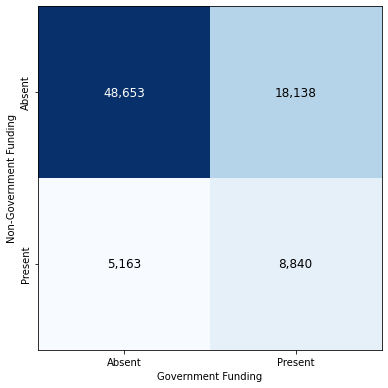

In [31]:
import matplotlib.pyplot as plt
import numpy as np


# =============================================================================
# Visualize the overall 2×2 contingency table
# =============================================================================

table_values = contingency_table.to_numpy()

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

# Use a sequential blue color palette for the heatmap.
image = ax.imshow(
    table_values,
    cmap="Blues"
)


# =============================================================================
# Add cell counts with adaptive text colors
# =============================================================================

# Use the midpoint of the heatmap color scale as the threshold.
threshold = (
    table_values.min()
    + table_values.max()
) / 2

for i in range(table_values.shape[0]):
    for j in range(table_values.shape[1]):

        cell_value = table_values[i, j]

        # Use white text for dark cells and black text for light cells.
        text_color = (
            "white"
            if cell_value > threshold
            else "black"
        )

        ax.text(
            j,
            i,
            f"{cell_value:,}",
            ha="center",
            va="center",
            fontsize=12,
            color=text_color
        )


# =============================================================================
# Customize axis labels
# =============================================================================

ax.set_xticks(
    [0, 1]
)

ax.set_xticklabels(
    [
        "Absent",
        "Present"
    ]
)

ax.set_yticks(
    [0, 1]
)

ax.set_yticklabels(
    [
        "Absent",
        "Present"
    ],
    rotation=90,
    va="center"
)

ax.set_xlabel(
    "Government Funding"
)

ax.set_ylabel(
    "Non-Government Funding"
)

# ax.set_title(
#     "Co-occurrence of Government and Non-Government Funding in LIS"
# )

# =============================================================================
# Save the figure
# =============================================================================

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_overall_2x2_contingency_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Overall LIS: Odds Ratio + 95% CI visualization

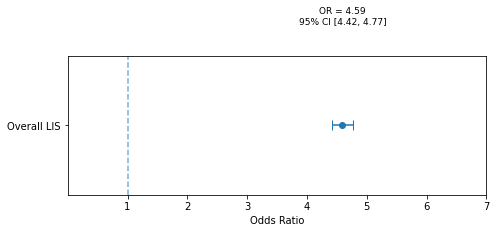

In [44]:
# =============================================================================
# Visualize the overall odds ratio and 95% confidence interval
# =============================================================================

fig, ax = plt.subplots(
    figsize=(7, 3.5)
)

ax.errorbar(
    x=overall_odds_ratio,
    y=0,
    xerr=[
        [
            overall_odds_ratio
            - overall_ci_lower
        ],
        [
            overall_ci_upper
            - overall_odds_ratio
        ]
    ],
    fmt="o",
    capsize=5
)

# OR = 1 indicates no association.
ax.axvline(
    x=1,
    linestyle="--",
    alpha=0.6
)

ax.set_yticks(
    [0]
)

ax.set_yticklabels(
    ["Overall LIS"]
)

ax.set_xlabel(
    "Odds Ratio"
)

# =============================================================================
# Customize x-axis range and tick positions
# =============================================================================

ax.set_xlim(
    0,
    7
)

ax.set_xticks(
    [1, 2, 3, 4, 5, 6, 7]
)

# =============================================================================
# Add odds ratio and confidence interval
# =============================================================================

ax.text(
    overall_odds_ratio,
    0.08,
    (
        f"OR = {overall_odds_ratio:.2f}\n"
        f"95% CI "
        f"[{overall_ci_lower:.2f}, "
        f"{overall_ci_upper:.2f}]"
    ),
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_overall_odds_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Temporal analysis visualization

In [33]:
# =============================================================================
# Calculate predicted probabilities from the temporal logistic model
# =============================================================================

prediction_years = np.arange(
    2014,
    2025
)

prediction_df = pd.DataFrame(
    {
        "Year": np.repeat(
            prediction_years,
            2
        ),

        "Year_Centered": np.repeat(
            prediction_years - 2014,
            2
        ),

        "Government_Present": np.tile(
            [0, 1],
            len(prediction_years)
        )
    }
)

prediction_df[
    "Predicted_Probability"
] = temporal_model.predict(
    prediction_df
)

prediction_df[
    "Government_Status"
] = prediction_df[
    "Government_Present"
].map(
    {
        0: "Absent",
        1: "Present"
    }
)

display(
    prediction_df.head()
)

,Year,Year_Centered,Government_Present,Predicted_Probability,Government_Status
0,2014,0,0,0.036685,Absent
1,2014,0,1,0.257688,Present
2,2015,1,0,0.043114,Absent
3,2015,1,1,0.268198,Present
4,2016,2,0,0.050610,Absent


In [34]:
# =============================================================================
# Extract the temporal interaction effect
# =============================================================================

interaction_term = (
    "Government_Present:Year_Centered"
)

interaction_beta = (
    temporal_model.params[
        interaction_term
    ]
)

interaction_p = (
    temporal_model.pvalues[
        interaction_term
    ]
)

interaction_or = np.exp(
    interaction_beta
)

print(
    f"Interaction beta: "
    f"{interaction_beta:.4f}"
)

print(
    f"Interaction OR: "
    f"{interaction_or:.4f}"
)

print(
    f"P-value: "
    f"{interaction_p:.4g}"
)

Interaction beta: -0.1139
Interaction OR: 0.8923
P-value: 8.228e-64


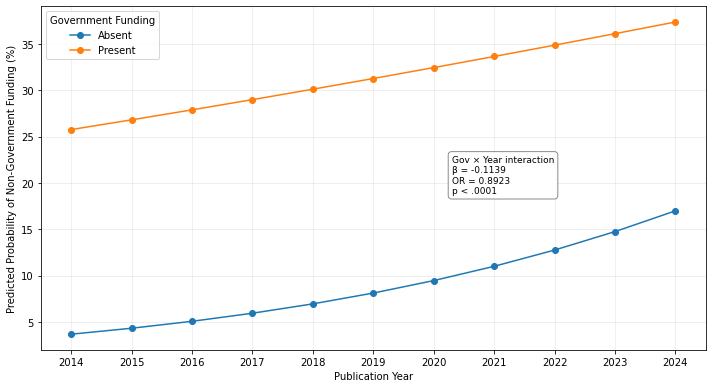

In [35]:
# =============================================================================
# Plot temporal predicted probabilities
# =============================================================================

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

for government_status in [
    "Absent",
    "Present"
]:

    subset = prediction_df[
        prediction_df[
            "Government_Status"
        ]
        == government_status
    ]

    ax.plot(
        subset["Year"],
        subset[
            "Predicted_Probability"
        ] * 100,
        marker="o",
        label=government_status
    )

# =============================================================================
# Add interaction annotation
# =============================================================================

interaction_text = (
    "Gov × Year interaction\n"
    f"β = {interaction_beta:.4f}\n"
    f"OR = {interaction_or:.4f}\n"
    "p < .0001"
)

ax.text(
    2020.3,
    23.0,
    interaction_text,
    fontsize=9,
    ha="left",
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)    


# =============================================================================
# Format the figure
# =============================================================================
   
ax.set_xlabel(
    "Publication Year"
)

ax.set_ylabel(
    "Predicted Probability of Non-Government Funding (%)"
)

ax.set_xticks(
    prediction_years
)

ax.legend(
    title="Government Funding"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_temporal_predicted_probability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12-1. Journal Quartile: Forest plot

In [36]:
# =============================================================================
# Calculate odds ratios by journal quartile
# =============================================================================

quartile_or_results = []

for quartile in [
    "Q1",
    "Q2",
    "Q3",
    "Q4"
]:

    subset = lis_quartile_df[
        lis_quartile_df[
            "Journal_Quartile"
        ]
        == quartile
    ]

    table = pd.crosstab(
        subset[
            "Non_Government_Present"
        ],
        subset[
            "Government_Present"
        ]
    ).reindex(
        index=[0, 1],
        columns=[0, 1],
        fill_value=0
    )

    a = table.loc[0, 0]
    b = table.loc[0, 1]
    c = table.loc[1, 0]
    d = table.loc[1, 1]

    odds_ratio_q = (
        a * d
    ) / (
        b * c
    )

    log_or_se = np.sqrt(
        1 / a
        + 1 / b
        + 1 / c
        + 1 / d
    )

    lower_ci = np.exp(
        np.log(
            odds_ratio_q
        )
        - 1.96 * log_or_se
    )

    upper_ci = np.exp(
        np.log(
            odds_ratio_q
        )
        + 1.96 * log_or_se
    )

    quartile_or_results.append(
        {
            "Quartile": quartile,
            "Odds_Ratio": odds_ratio_q,
            "CI_Lower": lower_ci,
            "CI_Upper": upper_ci,
            "N": len(subset)
        }
    )

quartile_or_df = pd.DataFrame(
    quartile_or_results
)

display(
    quartile_or_df.round(3)
)

,Quartile,Odds_Ratio,CI_Lower,CI_Upper,N
0,Q1,3.531,3.357,3.714,40645
1,Q2,4.346,3.928,4.808,13683
2,Q3,5.275,4.794,5.804,14731
3,Q4,8.847,7.706,10.157,11735


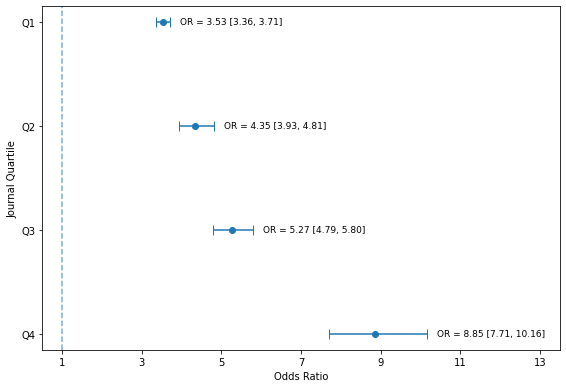

In [37]:
# =============================================================================
# Forest plot of government/non-government association by journal quartile
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

y_positions = np.arange(
    len(quartile_or_df)
)

ax.errorbar(
    quartile_or_df[
        "Odds_Ratio"
    ],
    y_positions,
    xerr=[
        quartile_or_df[
            "Odds_Ratio"
        ]
        - quartile_or_df[
            "CI_Lower"
        ],

        quartile_or_df[
            "CI_Upper"
        ]
        - quartile_or_df[
            "Odds_Ratio"
        ]
    ],
    fmt="o",
    capsize=5
)

# OR = 1 indicates no association.
ax.axvline(
    x=1,
    linestyle="--",
    alpha=0.6
)

ax.set_yticks(
    y_positions
)

ax.set_yticklabels(
    quartile_or_df[
        "Quartile"
    ]
)

ax.set_xlabel(
    "Odds Ratio"
)

ax.set_ylabel(
    "Journal Quartile"
)

# ax.set_title(
#     "Government–Non-Government Funding Association by LIS Journal Quartile"
# )

ax.invert_yaxis()


# =============================================================================
# Customize x-axis range and tick positions
# =============================================================================

X_MIN = 0.5
X_MAX = 13.5

ax.set_xlim(
    X_MIN,
    X_MAX
)

ax.set_xticks(
    [1, 3, 5, 7, 9, 11, 13]
)


# =============================================================================
# Add odds ratio and confidence interval labels
# =============================================================================

for y_position, row in quartile_or_df.iterrows():

    ax.text(
        row["CI_Upper"] + 0.25,
        y_position,
        (
            f"OR = {row['Odds_Ratio']:.2f} "
            f"[{row['CI_Lower']:.2f}, "
            f"{row['CI_Upper']:.2f}]"
        ),
        va="center",
        fontsize=9
    )

# =============================================================================
# Adjust layout and save the figure
# =============================================================================

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_quartile_odds_ratio_forest_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12-2. Quartile co-funding proportion

In [38]:
# =============================================================================
# Create the publication-level funding configuration
# =============================================================================

def assign_funding_configuration(row):
    """
    Assign each publication to one mutually exclusive funding category
    based on government and non-government funding presence.
    """

    gov = row["Government_Present"]
    non_gov = row["Non_Government_Present"]

    if gov == 1 and non_gov == 1:
        return "Government/Non-government"

    if gov == 1 and non_gov == 0:
        return "Government-only"

    if gov == 0 and non_gov == 1:
        return "Non-government-only"

    if gov == 0 and non_gov == 0:
        return "No funders"

    raise ValueError(
        f"Unexpected combination: "
        f"Government_Present={gov}, "
        f"Non_Government_Present={non_gov}"
    )


lis_quartile_df["Funding_Configuration"] = (
    lis_quartile_df.apply(
        assign_funding_configuration,
        axis=1
    )
)

In [39]:
print(
    lis_quartile_df[
        "Funding_Configuration"
    ]
    .value_counts()
)

display(
    lis_quartile_df[
        [
            "Journal_Quartile",
            "Government_Present",
            "Non_Government_Present",
            "Funding_Configuration"
        ]
    ].head(10)
)

No funders                   48653
Government-only              18138
Government/Non-government     8840
Non-government-only           5163
Name: Funding_Configuration, dtype: int64


,Journal_Quartile,Government_Present,Non_Government_Present,Funding_Configuration
0,Q2,0,0,No funders
1,Q2,0,0,No funders
2,Q2,1,0,Government-only
3,Q2,0,0,No funders
4,Q2,0,0,No funders
5,Q2,0,0,No funders
6,Q2,0,0,No funders
7,Q2,0,0,No funders
8,Q2,1,0,Government-only
9,Q2,0,0,No funders


In [40]:
# =============================================================================
# Define the order of funding configuration categories
# =============================================================================

FUNDING_CATEGORIES = [
    "Government-only",
    "Non-government-only",
    "Government/Non-government",
    "No funders"
]

In [41]:
# =============================================================================
# Calculate funding configuration distribution by journal quartile
# =============================================================================

quartile_distribution = pd.crosstab(
    lis_quartile_df[
        "Journal_Quartile"
    ],
    lis_quartile_df[
        "Funding_Configuration"
    ],
    normalize="index"
) * 100

quartile_distribution = (
    quartile_distribution
    .reindex(
        columns=FUNDING_CATEGORIES,
        fill_value=0
    )
)

display(
    quartile_distribution.round(2)
)

Funding_Configuration,Government-only,Non-government-only,Government/Non-government,No funders
Journal_Quartile,,,,
Q1,30.82,6.62,15.22,47.34
Q2,14.39,7.64,6.70,71.27
Q3,16.29,6.56,8.18,68.96
Q4,10.58,3.92,4.53,80.96


In [42]:
# =============================================================================
# Define funding configuration categories and colors
# =============================================================================

FUNDING_CATEGORIES = [
    "Government-only",
    "Non-government-only",
    "Government/Non-government",
    "No funders"
]

FUNDING_COLORS = {
    "Government-only": "tab:blue",
    "Non-government-only": "tab:orange",
    "Government/Non-government": "tab:green",
    "No funders": "lightgray"
}

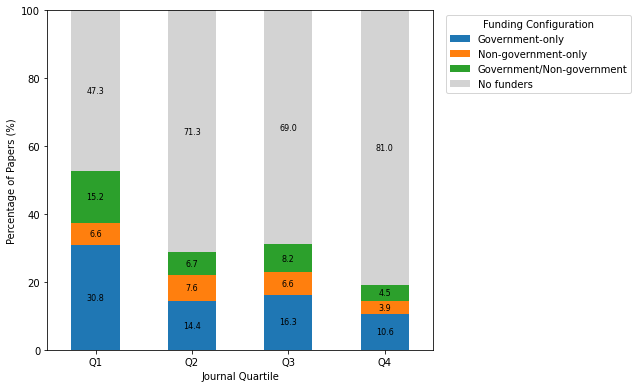

In [43]:
# =============================================================================
# Plot funding configurations by journal quartile
# =============================================================================

ax = quartile_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5.5),
    color=[
        FUNDING_COLORS[
            category
        ]
        for category in FUNDING_CATEGORIES
    ]
)

ax.set_xlabel(
    "Journal Quartile"
)

ax.set_ylabel(
    "Percentage of Papers (%)"
)

ax.set_ylim(
    0,
    100
)


# =============================================================================
# Display Q1-Q4 labels horizontally
# =============================================================================

ax.tick_params(
    axis="x",
    labelrotation=0
)


# =============================================================================
# Add percentage labels inside each bar segment
# =============================================================================

for patch in ax.patches:

    width = patch.get_width()
    height = patch.get_height()

    x_position = (
        patch.get_x()
        + width / 2
    )

    y_position = (
        patch.get_y()
        + height / 2
    )

    # Add a label only when the segment has a positive value.
    if height > 0:

        ax.text(
            x_position,
            y_position,
            f"{height:.1f}",
            ha="center",
            va="center",
            fontsize=8
        )


# =============================================================================
# Add legend
# =============================================================================

ax.legend(
    title="Funding Configuration",
    bbox_to_anchor=(
        1.02,
        1
    ),
    loc="upper left"
)


# =============================================================================
# Save the figure
# =============================================================================

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "LIS_quartile_funding_configuration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()